# The GCM model of categorization

How do people sort new objects into categories? The generalized context
model (GCM) says: by their similarity to the objects that they already
know. Lee & Wagenmakers (2013, chapter 17) fit the GCM to a category
learning experiment. This case study takes the PyMC version of the model
with individual differences and uses it in `elicito` with the PyMC
adapter.

The case study has three parts:

1. **Translate.** One call turns the PyMC model into a TensorFlow model.
2. **Validate.** The two models give the same samples. The TensorFlow model
   is fast enough for an elicitation.
3. **Elicit.** Two simulated experts give their knowledge about the
   category decisions. `elicito` learns a prior from each expert. PyMC
   then fits the model with each prior.

**Main results**

- The two models give the same distributions: the largest KS distance is
  0.022.
- The translated model draws 10 000 samples 4 to 5 times faster than
  PyMC.
- The elicited quantiles agree with the quantiles of both experts, for
  all 8 stimuli.
- The participants differ: some attend to dimension 1, others to
  dimension 2. An expert prior that allows only one kind of attention
  holds the other participants at its bound.

> **Note:** the adapter needs Python 3.12 or later and the optional
> dependency `pymc`. Install it with `pip install "elicito[pymc]"`.

In [1]:
import os

os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
# mkdocs runs the notebook in the repository root; the data are next to it
if os.path.isdir("docs/case-studies"):
    os.chdir("docs/case-studies")

In [2]:
import time
from typing import Any

import matplotlib.pyplot as plt
import numpy as np
import pymc as pm
import tensorflow as tf
import tensorflow_probability as tfp
from matplotlib.patches import Patch
from scipy import io, stats

import elicito as el
from elicito.adapter import pymc as adapter_pymc

tfd = tfp.distributions

SEED = tf.constant([2013, 17], dtype=tf.int32)
DRAWS = 10_000
TOL = 0.05  # largest KS distance D that shows agreement

In [3]:
import logging

# hide the INFO messages of pm.sample; the progress bar stays
logging.getLogger("pymc").setLevel(logging.WARNING)

# colours of the figures: one fixed colour for each entity
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#8a8984"
plt.rcParams.update(
    {
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": "#e6e5e1",
        "grid.linewidth": 0.6,
        "axes.axisbelow": True,
        "axes.titlesize": "medium",
        "legend.frameon": False,
    }
)

## The categorization task

In the experiment of Kruschke (1993), 40 participants learn to sort 8
stimuli into two categories, A and B. The stimuli differ on two
dimensions. Each participant sees each stimulus 8 times.

The figure shows, for each stimulus, how often the participants choose
category A. A bar is the mean over the participants. A dot is one
participant.

In [4]:
matdata = io.loadmat("data/KruschkeData.mat")
nstim, nsubj = 8, 40
d1, d2 = matdata["d1"], matdata["d2"]  # distances on dimension 1 and 2
a = matdata["a"][0]  # the category of each stimulus: 1 for A, 2 for B
y = matdata["x"].T  # A decisions, shape (stimulus, participant), of 8 trials

# one axis for the participants: distances (stimulus, stimulus, participant)
d1_t = np.tile(d1[:, :, None], [1, 1, nsubj])
d2_t = np.tile(d2[:, :, None], [1, 1, nsubj])
# in_a[i, j] is 1 if stimulus j is in category A
in_a = np.tile(2 - a, [nstim, 1])[:, :, None]

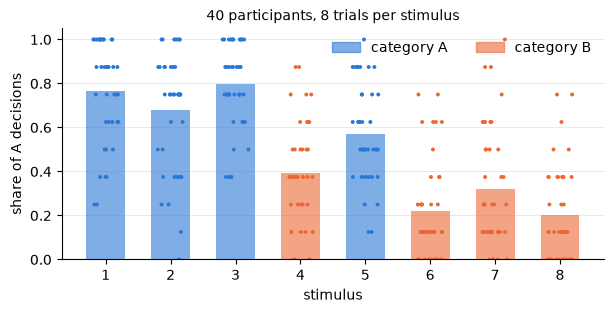

In [5]:
share_a = y / nstim
stimuli = np.arange(1, nstim + 1)
colors = [BLUE if category == 1 else ORANGE for category in a]

fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(stimuli, share_a.mean(axis=1), color=colors, alpha=0.6, width=0.6)
jitter = np.random.default_rng(1).uniform(-0.2, 0.2, size=share_a.shape)
ax.scatter(
    (stimuli[:, None] + jitter).ravel(),
    share_a.ravel(),
    s=8,
    color=np.repeat(colors, nsubj),
    lw=0,
)
ax.set(
    xlabel="stimulus",
    ylabel="share of A decisions",
    xticks=stimuli,
    ylim=(0, 1.05),
    title=f"{nsubj} participants, {nstim} trials per stimulus",
)
ax.grid(axis="x", visible=False)
ax.legend(
    handles=[
        Patch(color=BLUE, alpha=0.6, label="category A"),
        Patch(color=ORANGE, alpha=0.6, label="category B"),
    ],
    loc="upper right",
    ncols=2,
)
plt.show()

The participants put the stimuli 1, 2, 3 and 5 mostly in category A, and
the stimuli 4, 6, 7 and 8 mostly in category B. The dots spread over the
whole range: the participants differ much.

## The model

Each participant $p$ has two parameters:

- $c_p$, the **generalization**. A large value means that the similarity
  of two stimuli falls fast with their distance.
- $w_p$, the **attention** to dimension 1. Dimension 2 gets the attention
  $1 - w_p$.

The similarity of the stimuli $i$ and $j$ falls with their distance
$d_{ij}$ on the two dimensions:

$$s_{ijp} = \exp\bigl(-c_p \, (w_p d^{(1)}_{ij} + (1 - w_p) d^{(2)}_{ij})\bigr).$$

Participant $p$ chooses category A for stimulus $i$ with the probability

$$r_{ip} = \frac{b \sum_{j \in A} s_{ijp}}
{b \sum_{j \in A} s_{ijp} + (1 - b) \sum_{j \in B} s_{ijp}},$$

with the response bias $b = 0.5$. The number of A decisions in 8 trials
is

$$y_{ip} \sim \operatorname{Binomial}(8, r_{ip}), \qquad
c_p \sim \operatorname{Uniform}(0, 5), \qquad
w_p \sim \operatorname{Uniform}(0, 1).$$

The PyMC model follows the rules of [Use a PyMC model][use-a-pymc-model]:
each input of a prior is a named `pm.Data` node. The 40 participants
share these inputs, so `elicito` learns one prior for all of them.

In [6]:
B = 0.5  # the response bias


def uniform_prior(name: str, lower: float, upper: float) -> Any:
    """Add a Uniform prior for each participant, with shared pm.Data bounds"""
    return pm.Uniform(
        name,
        lower=pm.Data(f"{name}_lower", lower),
        upper=pm.Data(f"{name}_upper", upper),
        shape=(1, 1, nsubj),
    )


with pm.Model() as model:
    c = uniform_prior("c", 0.0, 5.0)
    w = uniform_prior("w", 0.0, 1.0)

    similarity = pm.math.exp(-c * (w * d1_t + (1 - w) * d2_t))
    sum_a = pm.math.sum(in_a * similarity, axis=1)
    sum_b = pm.math.sum((1 - in_a) * similarity, axis=1)
    ri = pm.Deterministic("ri", B * sum_a / (B * sum_a + (1 - B) * sum_b))
    pm.Binomial("yi", p=ri, n=nstim, observed=y)

## From PyMC to TensorFlow

`adapter_pymc.parameters` lists the priors that `elicito` reads. A prior
with 40 elements gives 40 parameters, `c[0]` to `c[39]`.
`adapter_pymc.model` returns the translated model. It returns each
observed variable and each `pm.Deterministic` by name: here `yi` and `ri`.

In [7]:
parameters = adapter_pymc.parameters(model)
print(
    f"{len(parameters)} parameters:",
    ", ".join(p["name"] for p in parameters[:3]),
    "...",
)

generative_model = adapter_pymc.model(model)()

80 parameters: c[0], c[1], c[2] ...


## Do the two models agree?

Both models get the same priors. The TensorFlow model and `pm.draw` each
draw 10 000 samples. If the translation is correct, the two samples come
from the same distribution.

The Kolmogorov-Smirnov (KS) distance $D$ measures the largest difference
between the two cumulative distributions. With 10 000 draws, a value
below 0.05 shows agreement. Each output has one value for each stimulus
and participant. The table shows the largest $D$ of these 320 values.

In [8]:
def sample_priors(pymc_model: Any, draws: int, seed: Any) -> Any:
    """Sample the priors of a PyMC model in TensorFlow, shape (1, draws, P)"""
    parameters = adapter_pymc.parameters(pymc_model)
    seeds = tfp.random.split_seed(seed, n=len(parameters))
    columns = []
    for parameter, param_seed in zip(parameters, seeds):
        args = {
            arg: float(pymc_model[hyper["name"]].get_value())
            for arg, hyper in parameter["hyperparams"].items()
        }
        columns.append(parameter["family"](**args).sample(draws, seed=param_seed))
    return tf.stack(columns, axis=-1)[None]


OUTPUTS = ("ri", "yi")
seed_priors, seed_model = tfp.random.split_seed(SEED)
prior_samples = sample_priors(model, DRAWS, seed_priors)
tf_out = generative_model(prior_samples, seed=seed_model)
pm_out = pm.draw([model[name] for name in OUTPUTS], draws=DRAWS, random_seed=1)

# float32 and float64 differ in the last digits: round both, in float64
samples = {
    name: {
        "TensorFlow": np.asarray(tf_out[name][0], dtype=float)
        .reshape(DRAWS, -1)
        .round(6),
        "PyMC": np.asarray(pm_values, dtype=float).reshape(DRAWS, -1).round(6),
    }
    for name, pm_values in zip(OUTPUTS, pm_out)
}
distance = {
    name: max(
        stats.ks_2samp(
            pair["TensorFlow"][:, j], pair["PyMC"][:, j], method="asymp"
        ).statistic
        for j in range(pair["PyMC"].shape[1])
    )
    for name, pair in samples.items()
}

print(f"{'output':<8}{'TensorFlow mean, sd':>22}{'PyMC mean, sd':>18}{'D':>8}")
for name, pair in samples.items():
    tf_stats, pm_stats = (
        f"{values.mean():.2f}, {values.std():.2f}" for values in pair.values()
    )
    print(f"{name:<8}{tf_stats:>22}{pm_stats:>18}{distance[name]:>8.3f}")
assert max(distance.values()) < TOL

output     TensorFlow mean, sd     PyMC mean, sd       D
ri                  0.50, 0.36        0.50, 0.36   0.022
yi                  4.01, 3.07        4.01, 3.07   0.021


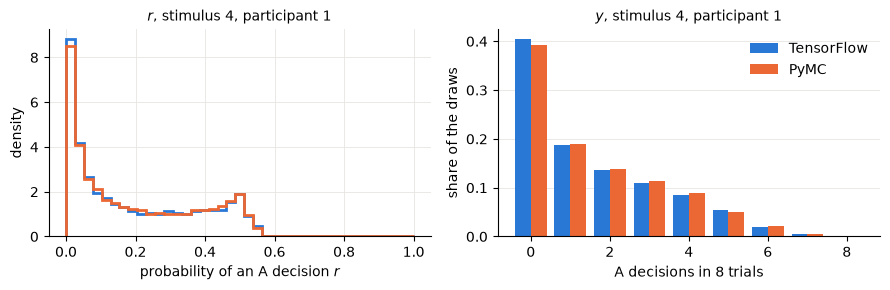

In [9]:
# the first participant and stimulus 4, the first stimulus of category B
EXAMPLE = 3 * nsubj

fig, (ax_r, ax_y) = plt.subplots(1, 2, figsize=(9, 3))
bins = np.linspace(0, 1, 40)
for (label, values), color in zip(samples["ri"].items(), (BLUE, ORANGE)):
    ax_r.hist(
        values[:, EXAMPLE],
        bins,
        density=True,
        histtype="step",
        lw=2,
        color=color,
        label=label,
    )
ax_r.set(
    xlabel="probability of an A decision $r$",
    ylabel="density",
    title="$r$, stimulus 4, participant 1",
)

counts = np.arange(nstim + 1)
for offset, ((label, values), color) in zip(
    (-0.2, 0.2), zip(samples["yi"].items(), (BLUE, ORANGE))
):
    share = np.bincount(values[:, EXAMPLE].astype(int), minlength=nstim + 1) / DRAWS
    ax_y.bar(counts + offset, share, width=0.4, color=color, label=label)
ax_y.set(
    xlabel="A decisions in 8 trials",
    ylabel="share of the draws",
    title="$y$, stimulus 4, participant 1",
)
ax_y.grid(axis="x", visible=False)
ax_y.legend()
fig.tight_layout()
plt.show()

The distributions of the two models overlap.

## How fast is the translated model?

During the elicitation, `elicito` runs the model at each step of the
search. A fast model is therefore important. We time one forward pass of
10 000 samples. Each model runs once before the timing, so the time does
not include the compilation.

PyMC draws one sample per call of its compiled function. The TensorFlow
model draws all samples in one call.

In [10]:
REPEATS = 5

draw_pymc = pm.compile([], [model[name] for name in OUTPUTS], random_seed=1)


def run_pymc() -> None:
    """Draw DRAWS samples with the compiled PyMC function"""
    for _ in range(DRAWS):
        draw_pymc()


def run_tensorflow() -> None:
    """Draw DRAWS samples with the translated model"""
    out = generative_model(prior_samples, seed=seed_model)
    _ = [value.numpy() for value in out.values()]


seconds = {}
for label, run in (("TensorFlow", run_tensorflow), ("PyMC", run_pymc)):
    run()  # warm-up
    times = []
    for _ in range(REPEATS):
        start = time.perf_counter()
        run()
        times.append(time.perf_counter() - start)
    seconds[label] = float(np.median(times))

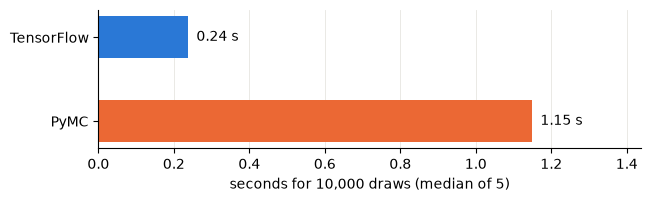

In [11]:
fig, ax = plt.subplots(figsize=(7, 1.8))
ax.barh(list(seconds), list(seconds.values()), color=[BLUE, ORANGE], height=0.5)
for i, value in enumerate(seconds.values()):
    ax.text(value, i, f"  {value:.2f} s", va="center")
ax.set(
    xlabel=f"seconds for {DRAWS:,} draws (median of {REPEATS})",
    xlim=(0, 1.25 * max(seconds.values())),
)
ax.grid(axis="y", visible=False)
ax.invert_yaxis()
plt.show()

The translated model is 4 to 5 times faster. The exact times depend on
the computer and its load.

## Two simulated experts

A simulated expert answers with the quantiles that a chosen prior gives.
A real expert gives these quantiles directly.

| Expert | $c$ | $w$ | Description |
| :-- | :-- | :-- | :-- |
| A | Uniform(0.5, 2.5) | Uniform(0.5, 1) | expects attention to dimension 1 |
| B | Uniform(0.5, 2.5) | Uniform(0, 0.5) | expects attention to dimension 2 |

Each expert gives, for each of the 8 stimuli, quantiles of the
probability that a participant chooses category A:

- **stimulus 1 to 8:** "Of 100 people who see this stimulus, how many put it in
  category A?"

An expert can answer this question from earlier experiments.

The expert answers each question with the 10 %, 25 %, 50 %, 75 % and
90 % quantiles. For the 10 % quantile, the question is: "Give a value
that is too low with a probability of 10 %."

In [12]:
def uniform(lower: float, upper: float) -> dict[str, Any]:
    """Return the same Uniform prior for each participant"""
    return {f"[{p}]": tfd.Uniform(lower, upper) for p in range(nsubj)}


def expert(w_lower: float, w_upper: float) -> dict[str, Any]:
    """Return the prior of a simulated expert, by parameter name"""
    c_prior = {f"c{key}": dist for key, dist in uniform(0.5, 2.5).items()}
    w_prior = {f"w{key}": dist for key, dist in uniform(w_lower, w_upper).items()}
    return c_prior | w_prior


EXPERTS = {"Expert A": expert(0.5, 1.0), "Expert B": expert(0.0, 0.5)}


def stimulus(i: int) -> Any:
    """Return the target function: the A probability of stimulus i"""

    def rate(ri: Any) -> Any:
        return ri[..., i, :]

    return rate


PROBS = (0.1, 0.25, 0.5, 0.75, 0.9)
targets = [
    el.quantiles(f"stimulus {i + 1}", output=stimulus(i), probs=PROBS)
    for i in range(nstim)
]

In [13]:
fits = {}
for name, ground_truth in EXPERTS.items():
    eliobj = el.Elicit(model, targets, seeds=(1, 2, 3), epochs=400, verbose=False)
    fits[name] = eliobj.fit(
        el.expert.simulator(ground_truth=ground_truth, num_samples=10_000)
    )

## Did the elicitation succeed?

The loss must go down and level off. The elicited quantiles must be near
the quantiles of the expert: this is the check of the elicitation.

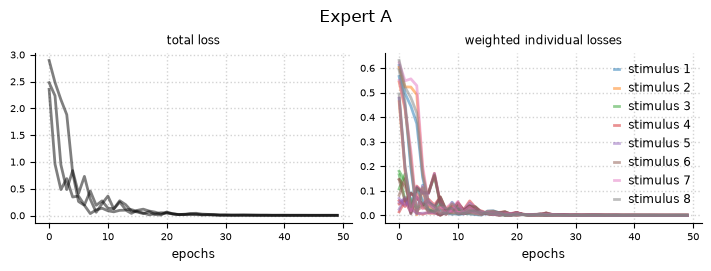

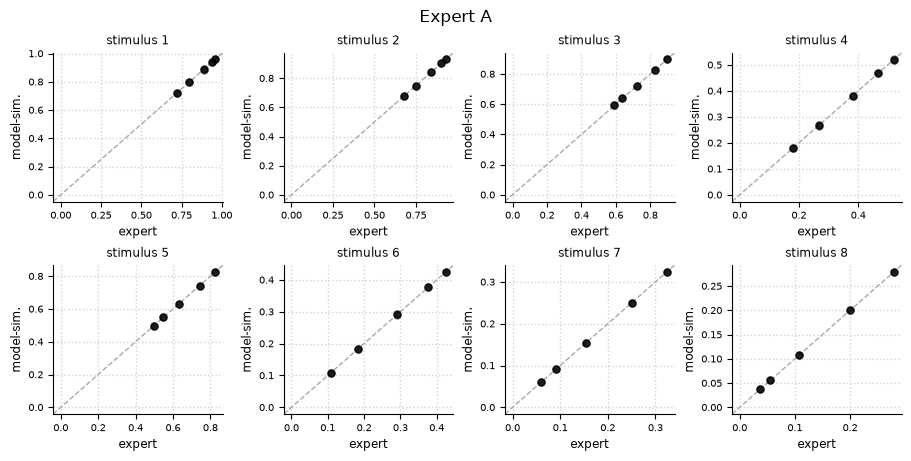

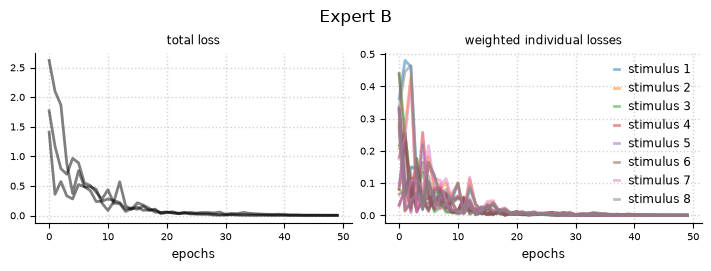

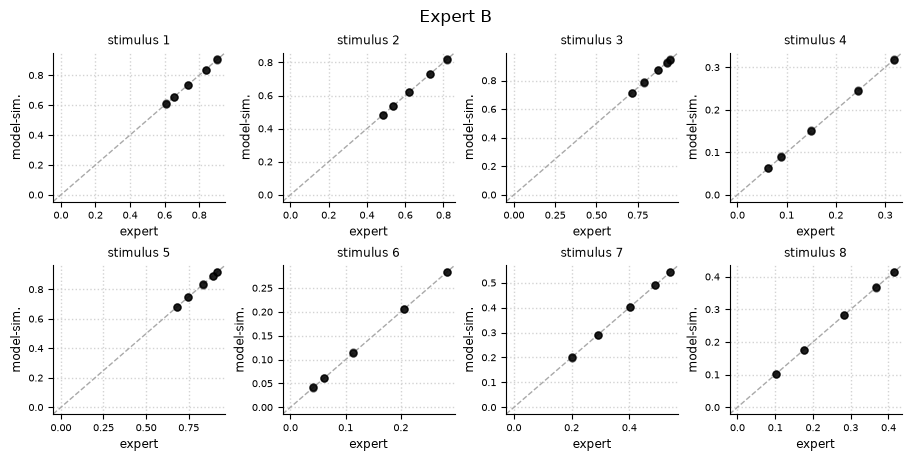

In [14]:
for name, fit in fits.items():
    fig, _ = fit.plot.loss(figsize=(7, 2.6))
    fig.suptitle(name)
    plt.show()
    fig, _ = fit.plot.elicits(cols=4, figsize=(9, 4.5))
    fig.suptitle(name)
    plt.show()

A Uniform prior has two bounds. The search can return them in the wrong
order, for example a lower bound of 1 and an upper bound of 0.5. The
samples are then the same, but PyMC needs `lower < upper`. We therefore
sort each pair of bounds. We use the replication with the lowest loss.

In [15]:
PARAMETERS = ("c", "w")


def bounds(fit: Any) -> dict[str, tuple[float, float]]:
    """Return the sorted Uniform bounds of each parameter, best replication"""
    values = fit.hyperparameters()
    return {
        name: tuple(sorted((values[f"{name}_lower"], values[f"{name}_upper"])))
        for name in PARAMETERS
    }


PRIORS = {"Book": {"c": (0.0, 5.0), "w": (0.0, 1.0)}}
PRIORS |= {name: bounds(fit) for name, fit in fits.items()}

## From prior to posterior

We now give each elicited prior back to the PyMC model with
`pm.set_data`. PyMC then fits the model to the data of all participants.
The book prior is the reference.

In [16]:
posteriors, predictives = {}, {}
for label, prior in PRIORS.items():
    with model:
        pm.set_data(
            {
                f"{name}_{side}": value
                for name, pair in prior.items()
                for side, value in zip(("lower", "upper"), pair)
            }
        )
        idata = pm.sample(1000, tune=1000, chains=4, random_seed=1, progressbar=True)
        pm.sample_posterior_predictive(
            idata, extend_inferencedata=True, random_seed=1, progressbar=False
        )
    # one row per draw, one column per participant
    posteriors[label] = {
        name: idata.posterior[name].values.reshape(-1, nsubj) for name in PARAMETERS
    }
    predictives[label] = idata.posterior_predictive

Output()

Output()

Output()

The figure compares the prior and the posterior of the attention $w$ for
three participants: the participant with the lowest, the median and the
highest posterior mean under the book prior.

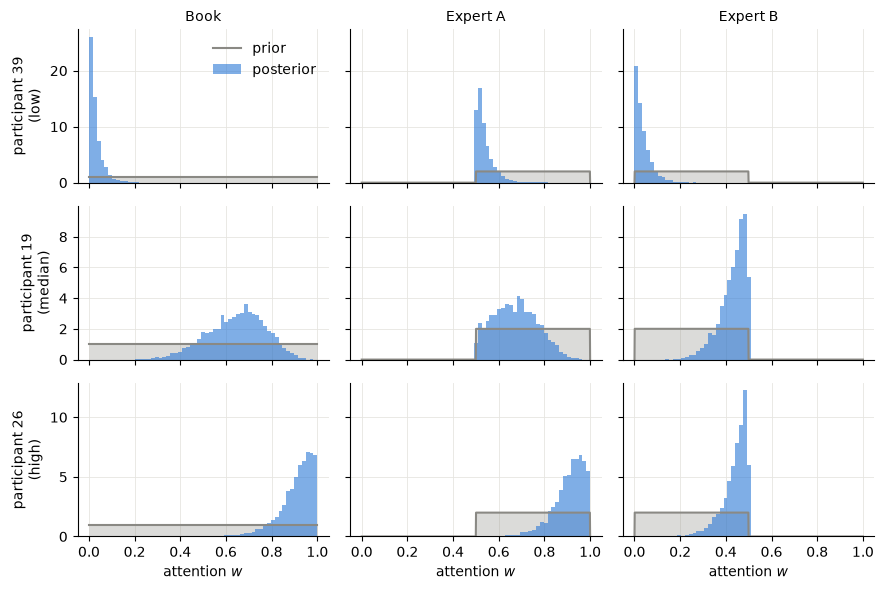

In [17]:
book_means = posteriors["Book"]["w"].mean(axis=0)
order = np.argsort(book_means)
EXAMPLES = {
    "low": order[0],
    "median": order[nsubj // 2],
    "high": order[-1],
}
grid = np.linspace(0, 1, 1000)

fig, axs = plt.subplots(
    len(EXAMPLES), len(PRIORS), figsize=(9, 6), sharex=True, sharey="row"
)
for row, (example, participant) in enumerate(EXAMPLES.items()):
    for col, (label, prior) in enumerate(PRIORS.items()):
        ax = axs[row, col]
        lower, upper = prior["w"]
        prior_density = stats.uniform(lower, upper - lower).pdf(grid)
        ax.fill_between(grid, prior_density, color=GREY, alpha=0.3, lw=0)
        ax.plot(grid, prior_density, color=GREY, lw=1.5, label="prior")
        ax.hist(
            posteriors[label]["w"][:, participant],
            bins=np.linspace(0, 1, 60),
            density=True,
            histtype="stepfilled",
            color=BLUE,
            alpha=0.6,
            label="posterior",
        )
        if row == 0:
            ax.set_title(label)
        if col == 0:
            ax.set_ylabel(f"participant {participant + 1}\n({example})")
        if row == len(EXAMPLES) - 1:
            ax.set_xlabel("attention $w$")
axs[0, 0].legend()
fig.tight_layout()
plt.show()

The next figure shows all 40 participants. Each line is the 90 % interval
of the posterior of $w$, and each dot the posterior mean. The participants
are sorted by their posterior mean under the book prior.

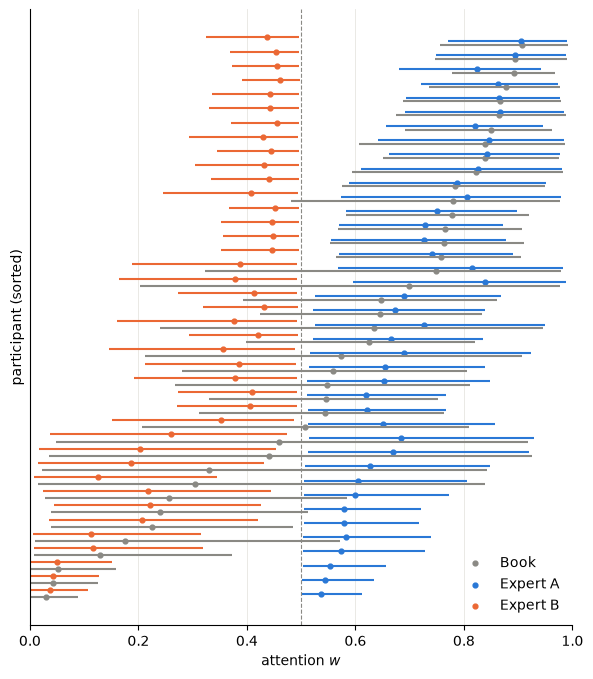

In [18]:
COLORS = {"Book": GREY, "Expert A": BLUE, "Expert B": ORANGE}

fig, ax = plt.subplots(figsize=(7, 8))
for offset, (label, posterior) in zip((-0.25, 0.0, 0.25), posteriors.items()):
    w_draws = posterior["w"][:, order]
    low, high = np.quantile(w_draws, [0.05, 0.95], axis=0)
    rows = np.arange(nsubj) + offset
    ax.hlines(rows, low, high, color=COLORS[label], lw=1.5)
    ax.scatter(w_draws.mean(axis=0), rows, color=COLORS[label], s=12, label=label)
ax.axvline(0.5, color=GREY, lw=0.8, ls="--")
ax.set(
    xlabel="attention $w$",
    ylabel="participant (sorted)",
    yticks=[],
    xlim=(0, 1),
)
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
plt.show()

- **Book prior.** The posterior means of $w$ go from near 0 to near 1.
  Some participants attend to dimension 1, others to dimension 2.
- **Expert A** allows only $w \geq 0.5$. The participants who attend to
  dimension 2 stay near the bound 0.5. The other participants keep almost
  the posterior of the book prior.
- **Expert B** allows only $w \leq 0.5$. The participants who attend to
  dimension 1 now stay near the bound 0.5.

Each participant has only 8 trials for each stimulus. The prior therefore
has a strong effect on the posterior of each participant.

## Does the model fit the data?

A posterior predictive check simulates new data from the fitted model,
once for each posterior draw. The figure repeats the first figure, with
one panel for each prior.

The dots are the observed shares of A decisions, averaged over the
participants. A line is the 90 % interval of the simulated average.

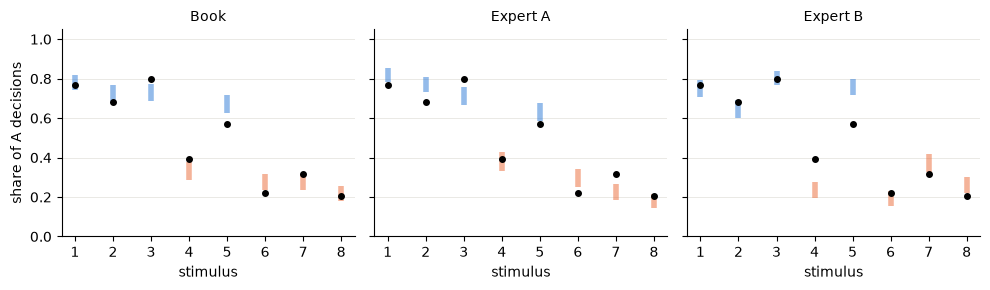

In [19]:
fig, axs = plt.subplots(1, len(PRIORS), figsize=(10, 3), sharey=True)
for ax, (label, predictive) in zip(axs, predictives.items()):
    rep = predictive["yi"].values.reshape(-1, nstim, nsubj) / nstim
    low, high = np.quantile(rep.mean(axis=-1), [0.05, 0.95], axis=0)
    ax.vlines(stimuli, low, high, color=colors, lw=4, alpha=0.5)
    ax.plot(stimuli, share_a.mean(axis=1), "o", color="black", ms=4)
    ax.set(title=label, xlabel="stimulus", xticks=stimuli, ylim=(0, 1.05))
    ax.grid(axis="x", visible=False)
axs[0].set_ylabel("share of A decisions")
fig.tight_layout()
plt.show()

- **Book prior.** The observed means of 6 of the 8 stimuli are inside or
  at the edge of the 90 % intervals. Stimulus 3 is above (0.80), and
  stimulus 5 below (0.57).
- **Expert A.** The intervals are similar. Stimuli 3 and 7 are above.
- **Expert B.** The intervals of stimuli 4, 5 and 7 are far from the
  observed means. The low attention $w$ of expert B gives the wrong
  pattern for these stimuli.

## Takeaways

- **Translation.** One call translates the PyMC model with 80 parameters.
  The largest KS distance is 0.022.
- **Speed.** The translated model is 4 to 5 times faster than PyMC.
- **Elicitation.** The elicited quantiles agree with the experts for all
  8 stimuli.
- **Population priors.** The 40 participants share one prior. If the
  expert expects one kind of participant, the prior is wrong for the
  others. A Uniform prior then holds their posterior at its bound.
- **Posterior predictive check.** The wrong prior of expert B shows as a
  misfit for three of the 8 stimuli.

## Appendix

The PyMC3 model comes from the notebook
[TheGCMModelofCategorization.ipynb](https://github.com/pymc-devs/pymc-resources/blob/main/BCM/CaseStudies/TheGCMModelofCategorization.ipynb)
of pymc-resources (MIT licence). See the [case studies](index.md) for the
credit.

In [20]:
import importlib.metadata
import sys

print(f"Python {sys.version.split()[0]}")
for package in ("elicito", "pymc", "tensorflow", "tensorflow-probability"):
    print(f"{package} {importlib.metadata.version(package)}")

Python 3.13.13
elicito 0.7.1a1
pymc 6.3.2
tensorflow 2.20.0
tensorflow-probability 0.25.0


## References

- Kruschke, J. K. (1993). Human category learning: Implications for
  backpropagation models. *Connection Science*, 5, 3-36.
- Lee, M. D., & Wagenmakers, E.-J. (2013). *Bayesian Cognitive Modeling: A
  Practical Course*. Cambridge University Press.